# **2026-1 TÉCNICAS AVANZADAS DE DATA MINING Y SISTEMAS INTELIGENTES (INF659) **
## **Examen Parcial 2026-1**  
### **Descripción de la tarea**

El objetivo de esta tarea es predecir si un paciente tiene rastros de neumonía en sus pulmones relacionados con COVID-19. El conjunto de datos a utilizar contiene tomografías computarizadas (TC) de pulmón humano anonimizadas con hallazgos relacionados con COVID-19 (anormales), así como de pulmones sano (normales). Las tomografías computarizadas se obtuvieron entre el 1 de marzo de 2020 y el 25 de abril de 2020, y fueron proporcionadas por hospitales municipales en Moscú, Rusia.

**Dataset (Fuente):** https://www.medrxiv.org/content/10.1101/2020.05.20.20100362v1

Vamos a usar una **porción del dataset** que consta de 100 volúmenes de imágenes para cada clase (normal y anormal). Esto es debido que el dataset original contiene muchos más volúmenes de imágenes, lo que dificultaría la experimentación y provocaría que tome más tiempo.

In [ ]:
import tensorflow as tf

from tensorflow.keras.layers import Input #Aquí van el resto de capas que se necesiten para construir el modelo
from tensorflow.keras import Model
from tensorflow.keras.optimizers.schedules import ExponentialDecay
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import plot_model
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import load_model

from tensorflow.keras import backend as K

tf.random.set_seed(0) #No modificar esta línea

In [ ]:
import os
import nibabel as nib
from scipy import ndimage
import numpy as np
from sklearn.model_selection import train_test_split
from random import randint
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

%matplotlib inline

## **NOTA: Los archivos son descargados en el espacio temporal de Google Drive. Para tenerlos permanentemente y evitar tener que descargarlos nuevamente, se recomienda montar su Google Drive y guardar ahí los archivos**

**Descarga de vólumenes de imágenes de tomografías computarizadas**

In [ ]:
!git clone https://github.com/iapucp/CT-Scans-100-samples.git

Cloning into 'CT-Scans-100-samples'...
remote: Enumerating objects: 204, done.
remote: Total 204 (delta 0), reused 0 (delta 0), pack-reused 204 (from 1)
Receiving objects: 100% (204/204), 1.96 GiB | 42.47 MiB/s, done.
Updating files: 100% (200/200), done.


In [ ]:
%mv CT-Scans-100-samples/CT-Normal /content/CT-Normal

In [ ]:
%mv CT-Scans-100-samples/CT-Abnormal /content/CT-Abnormal

In [ ]:
%rm -rf CT-Scans-100-samples/

**Comprobación que se haya obtenido el contenido de los archivos .zip**

In [ ]:
%ls

CT-Abnormal/  CT-Normal/  sample_data/


## Get paths of CT scans

In [ ]:
normal_scan_paths = [("/content/CT-Normal/" + x) for x in os.listdir("CT-Normal")]

abnormal_scan_paths = [("/content/CT-Abnormal/" + x) for x in os.listdir("CT-Abnormal")]

print("CT-Normal scan with length of: {}".format(len(normal_scan_paths)))
print("CT-Abnormal scan with length of: {}".format(len(abnormal_scan_paths)))

CT-Normal scan with length of: 100
CT-Abnormal scan with length of: 100


In [ ]:
normal_scan_paths[:5]

['/content/CT-Normal/study_0082.nii.gz',
 '/content/CT-Normal/study_0063.nii.gz',
 '/content/CT-Normal/study_0076.nii.gz',
 '/content/CT-Normal/study_0094.nii.gz',
 '/content/CT-Normal/study_0012.nii.gz']

In [ ]:
abnormal_scan_paths[:5]

['/content/CT-Abnormal/study_0982.nii.gz',
 '/content/CT-Abnormal/study_0974.nii.gz',
 '/content/CT-Abnormal/study_1090.nii.gz',
 '/content/CT-Abnormal/study_0951.nii.gz',
 '/content/CT-Abnormal/study_0992.nii.gz']

## Pre-processing

Los archivos están en formato Nifti, con la extensión ".nii".
<br/>
<br/>
Las tomografías computarizadas (CT scans) almacenan la intensidad del vóxel, sin procesar, en unidades Hounsfield (HU), cuyo rango es desde -1024 a más de 2000.
<br/>
<br/>
Por encima de 400 se hace referencia a huesos con diferentes radiointensidades, por lo que se utiliza como el límite superior. Por ello, se utiliza un rango entre -1000 a 400 para normalizar las tomografías computarizadas.

In [ ]:
def normalize_scan(scan, min=-1000, max=400):
  # Scale the HU values to be between 0 and 1
  scan[scan < min] = min
  scan[scan > max] = max

  scan = (scan - min) / (max - min)

  scan = scan.astype("float32")

  return scan

def resize_scan(scan, desired_width, desired_height, desired_depth):
  # Get current depth
  current_depth = scan.shape[-1]
  current_width = scan.shape[0]
  current_height = scan.shape[1]

  # Compute depth factor
  depth = current_depth / desired_depth
  width = current_width / desired_width
  height = current_height / desired_height

  depth_factor = 1 / depth
  width_factor = 1 / width
  height_factor = 1 / height

  # Rotate the scan by 90 degrees, so the orientation is fixed
  scan = ndimage.rotate(scan, 90, reshape=False)

  # Resize across z-axis
  scan = ndimage.zoom(scan, (width_factor, height_factor, depth_factor), order=1)

  return scan

def preprocess_scan(path, width, height, depth):
  scan = nib.load(path).get_fdata()

  resized_scan = resize_scan(scan, width, height, depth)

  normalized_resized_scan = normalize_scan(resized_scan)

  return normalized_resized_scan

In [ ]:
width = 128
height = 128
depth = 64

**Pre-procesar las tomografías computarizadas. El pre-procesamiento consiste en cambiar el tamaño de las tomografías computarizadas para que tengan el shape (width, height, depth), cambiar la escala de los valores HU al rango 0 al 1.**

In [ ]:
%%time
normal_scans = np.array([preprocess_scan(path, width, height, depth) for path in normal_scan_paths])

CPU times: user 3min 22s, sys: 8.31 s, total: 3min 31s
Wall time: 3min 32s


In [ ]:
%%time
abnormal_scans = np.array([preprocess_scan(path, width, height, depth) for path in abnormal_scan_paths])

CPU times: user 3min 17s, sys: 7.89 s, total: 3min 25s
Wall time: 3min 26s


In [ ]:
assert normal_scans.shape == (len(normal_scan_paths), width, height, depth), "No se realizó correctamente el cambio de tamaño"

assert abnormal_scans.shape == (len(abnormal_scan_paths), width, height, depth), "No se realizó correctamente el cambio de tamaño"

In [ ]:
assert ((normal_scans.max() == 1) and (normal_scans.min() == 0)), "No se realizó correctamente la normalización"

assert ((abnormal_scans.max() == 1) and (abnormal_scans.min() == 0)), "No se realizó correctamente la normalización"

**Asignar las etiquetas a las tomografías computarizadas**

- **CT Normal Scans -> 0**

- **CT Abnormal Scans -> 1**

In [ ]:
normal_labels = np.array([0] * normal_scans.shape[0])
abnormal_labels = np.array([1] * abnormal_scans.shape[0])

In [ ]:
assert normal_labels.shape == (len(normal_scan_paths),), "No se realizó correctamente la asignación de etiquetas"

assert abnormal_labels.shape == (len(abnormal_scan_paths),), "No se realizó correctamente la asignación de etiquetas"

## Processing

**Juntando/Concatenando las tomografías computarizadas (normales con anormales) y sus respectivas etiquetas**

In [ ]:
scans = np.concatenate([normal_scans, abnormal_scans], axis=0)
del normal_scans, abnormal_scans #Borramos estas variables para ahorrar memoria

labels = np.concatenate([normal_labels, abnormal_labels], axis=0)
del normal_labels, abnormal_labels #Borramos estas variables para ahorrar memoria

In [ ]:
assert scans.shape == (len(normal_scan_paths) + len(abnormal_scan_paths), width, height, depth), "No se juntó correctamente las tomografías computarizadas"

assert labels.shape == (len(normal_scan_paths) + len(abnormal_scan_paths),), "No se juntó correctamente las etiquetas"

In [ ]:
index = 10

number_of_rows = 8
number_of_cols = 8

image, label = scans[index], labels[index]

CT scan shape (128, 128, 64) con label 0



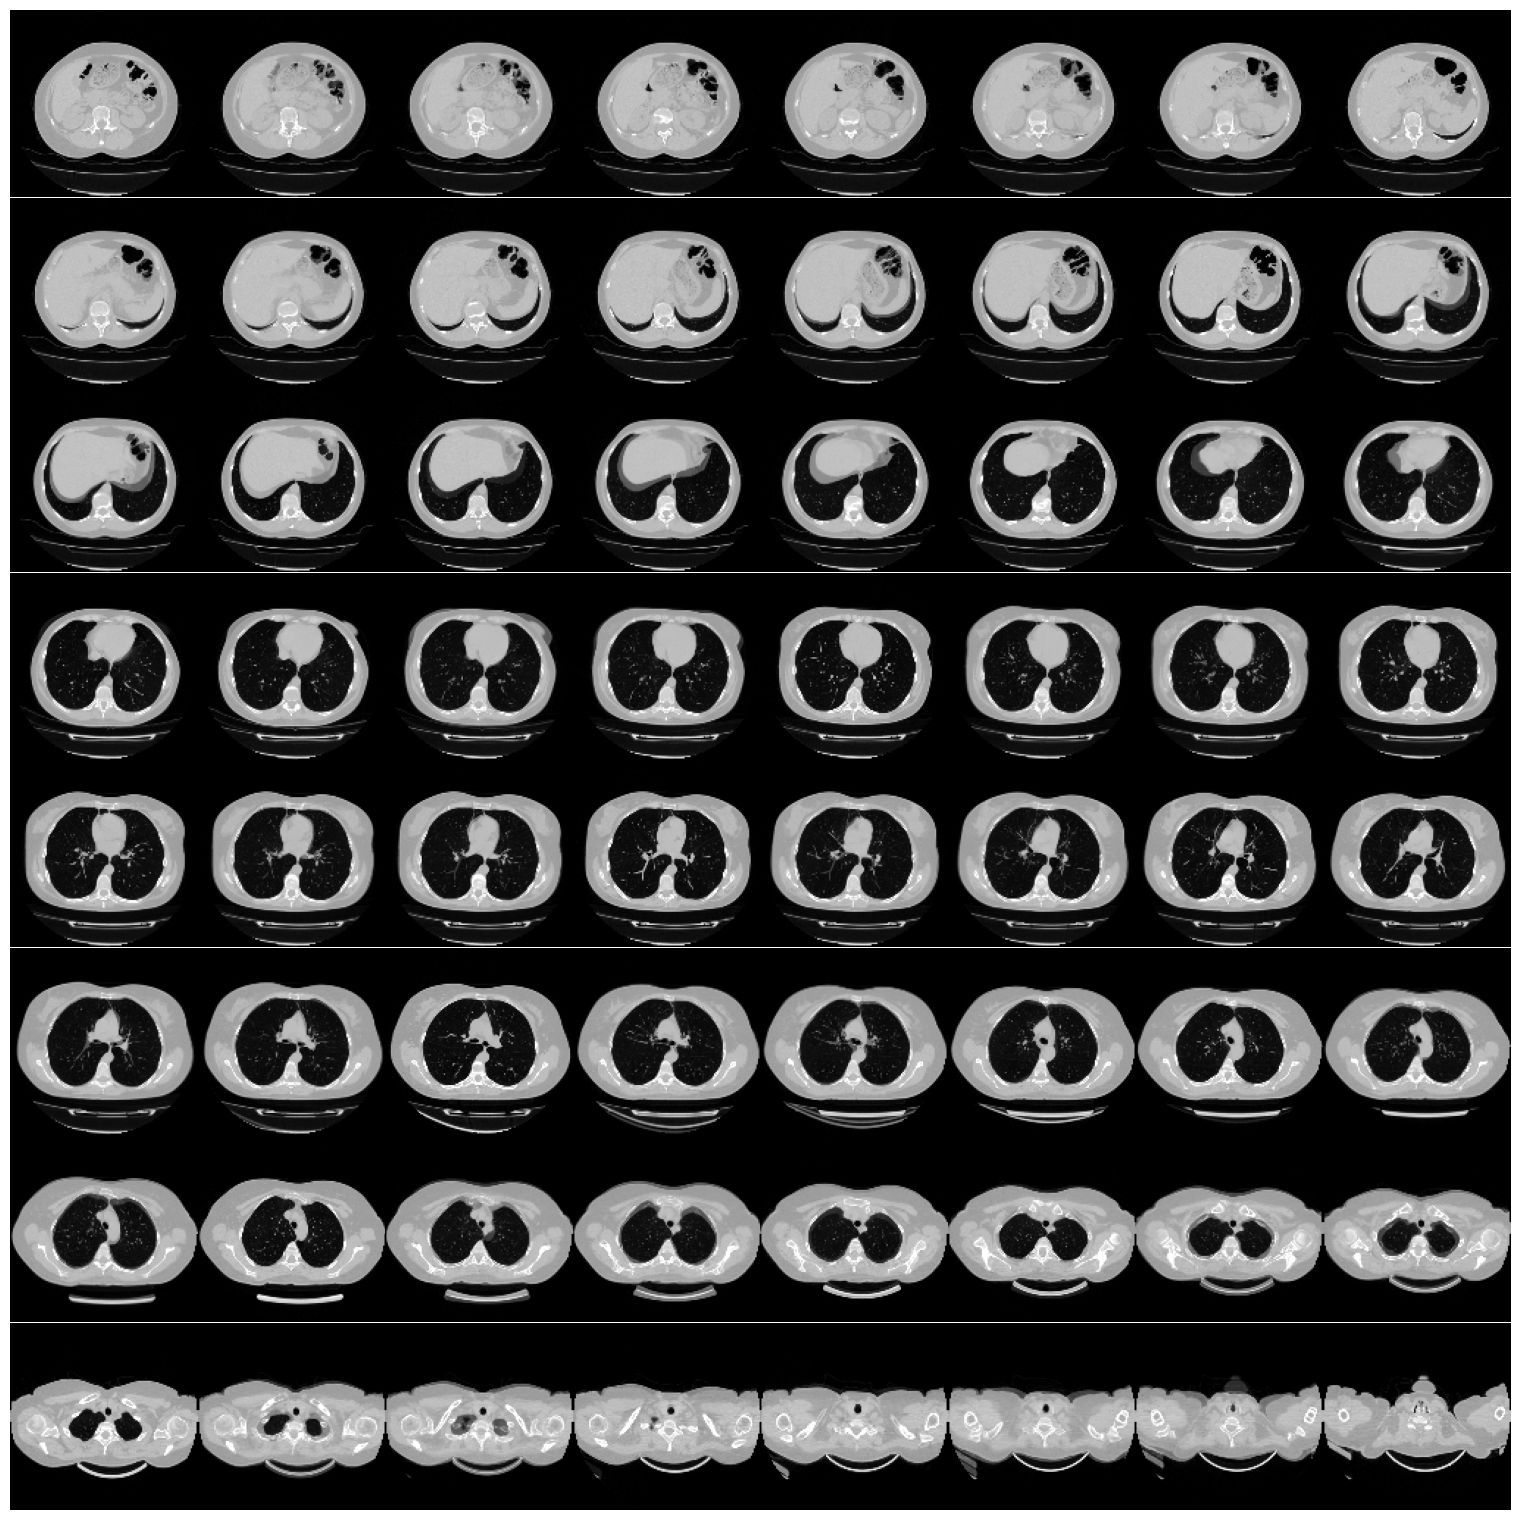

In [ ]:
print("CT scan shape {} con label {}\n".format(image.shape, label))

fig, axis = plt.subplots(number_of_rows, number_of_cols, figsize=(15, 15))

for i in range(number_of_rows):
  for j in range(number_of_cols):
    hue_selected = (i * number_of_rows) + j
    image_with_hue_selected = np.squeeze(image[:, :, hue_selected ]) #(width, height)

    axis[i, j].imshow(image_with_hue_selected, cmap="gray")
    axis[i, j].axis("off")

plt.subplots_adjust(wspace=0, hspace=0, left=0, right=1, bottom=0, top=1)

plt.show()

**Train test split STRATIFIED (https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)**

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(scans, labels, test_size=0.15, random_state=0, stratify=labels)

del scans #Borramos esta variable para ahorrar memoria

x_train.shape, y_train.shape, x_test.shape, y_test.shape

((170, 128, 128, 64), (170,), (30, 128, 128, 64), (30,))

**PREGUNTA 1 (2 punto)**

**Data Augmentation**

Analice la técnica de *data augmentation* usada.

- ¿En qué beneficiaría/perjudicaría al modelo?

- ¿Habría alguna diferencia si se entrena el modelo sin este *data augmentation*?

- ¿Ésta técnica de *data augmentation*, agrega nuevos volúmenes al corpus o sólo realiza transformaciones sobre los volúmenes existentes?

**AQUÍ SUS RESPUESTAS**

->

->

->

In [ ]:
from random import choice
from scipy import ndimage

@tf.function
def rotate(scan):
  def scipy_rotate(scan):
    # Define some rotation angles
    angles = [-20, -10, -5, 5, 10, 20]

    # Pick angles at random
    angle = choice(angles)

    # Rotate scan
    scan = ndimage.rotate(scan, angle, reshape=False)

    #Keep values between 0 and 1
    scan[scan < 0] = 0
    scan[scan > 1] = 1

    return scan

  augmented_scan = tf.numpy_function(scipy_rotate, [scan], tf.float32)

  return augmented_scan

def train_augmentation(scan, label):
  scan = rotate(scan)

  scan = tf.expand_dims(scan, axis=3) #Add 1 channel for Conv3D

  return scan, label

def test_augmentation(scan, label):
  scan = tf.expand_dims(scan, axis=3) #Add 1 channel for Conv3D

  return scan, label

## Preparing data for model

In [ ]:
batch_size = 2 #No modificar esta línea

In [ ]:
dataset_train = tf.data.Dataset.from_tensor_slices((x_train, y_train))

dataset_test = tf.data.Dataset.from_tensor_slices((x_test, y_test))

In [ ]:
dataset_train = dataset_train.shuffle(x_train.shape[0]).map(train_augmentation).batch(batch_size).prefetch(2)

dataset_test = dataset_test.shuffle(x_test.shape[0]).map(test_augmentation).batch(batch_size).prefetch(2)

## Model

**PREGUNTA 2 (10 puntos)**

Creación/Diseño/Construcción del modelo

- Explique el diseño final de su modelo

**Comience con un modelo base que use un par de capas convolucionales y densas para ver como se comporta dicho modelo (2 puntos). Luego, usando el paper de referencia, modifique su modelo hasta llegar a la versión final (5 puntos). Diseñe otra versión de su modelo usando sólo capas convolucionales, es decir, usando Global_Average_Pooling (3 puntos). De esta forma, podrá verificar la influencia de las capas (con sus respectivos parámetros) que agregue o quite a su modelo.**

**NOTA: No es lo mismo una capa convolucional con 1024 filtros que otra con 128.**

**Paper de referencia para construir su modelo (revisar la página 6): https://arxiv.org/abs/2007.13224**

**Github de referencia: https://github.com/hasibzunair/uniformizing-3D**

**A MODO DE REGISTRO, AQUÍ PUEDE IR GUARDANDO LAS DIFERENTES CONFIGURACIONES QUE HA IDO PROBANDO**

->

->

->

->

->

In [ ]:
K.clear_session()

inputs = Input(shape=(width, height, depth, 1))

.....

outputs = Dense(units=1, activation="sigmoid")(x)

model = Model(inputs=inputs, outputs=outputs)

**PREGUNTA 3 (2 punto)**

Establecimiento de parámetros del Exponential Decay

- Explique el efecto del *learning rate* en el entrenamiento, a causa de los parámetros elegidos

**Exponential Decay (https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/schedules/ExponentialDecay)**

**AQUÍ SU RESPUESTA**

->

In [ ]:
initial_learning_rate = 0.0001
lr_schedule = ExponentialDecay(initial_learning_rate, .....)

model.compile(optimizer=Adam(learning_rate=lr_schedule), loss="binary_crossentropy", metrics=["acc"])

In [ ]:
model.summary()

In [ ]:
plot_model(model, to_file="model.png", show_shapes=True)

### Train model

In [ ]:
def show_results(log):
  val_loss = log.history['val_loss']
  val_acc = log.history['val_acc']

  fig, axes = plt.subplots(1, 2, figsize=(14,4))
  ax1, ax2 = axes
  ax1.plot(log.history['loss'], label='train')
  ax1.plot(val_loss, label='test')
  ax1.set_xlabel('epoch'); ax1.set_ylabel('loss')
  ax2.plot(log.history['acc'], label='train')
  ax2.plot(val_acc, label='test')
  ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy')
  for ax in axes: ax.legend()



**PREGUNTA 4 (2 punto)**

Establecimiento de parámetros (epochs, patience) para el entrenamiento del modelo

- Explique el efecto de los parámetros *epochs* y *patience* al momento de entrenar su modelo

**Model Checkpoint (https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/ModelCheckpoint)**

**Early Stopping (https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping)**

**AQUÍ SU RESPUESTA**

->

In [ ]:
epochs = .....

checkpoint = ModelCheckpoint("model-epoch:{epoch:02d}-loss:{loss:.3f}-val_acc:{val_acc:.3f}-weights", monitor="val_acc", mode="max") #No modificar esta línea

early_stopping = EarlyStopping(monitor="val_acc", patience=....., mode="max")

callbacks = [checkpoint, early_stopping] #No modificar esta línea

**Se recomienda esperar 10 épocas para determinar si su modelo comienza a mejorar o no su "val_acc", porque al inicio puede estar estancado**

**Si en 10 épocas su modelo no mejora su "val_acc", se recomienda probar con otro modelo**

In [ ]:
log = model.fit(dataset_train, epochs=epochs, callbacks=callbacks, validation_data=dataset_test)

In [ ]:
show_results(log)

**PREGUNTA 4 (2 punto)**

- Explique como se realizan las convoluciones en 3 dimensiones (por ejemplo: cómo funcionan los filtros) respecto de las convoluciones en 2 dimensiones

- ¿Usted cree que podría mejorar sus resultados usando *transfer-learning*?. Justifique su respuesta especificando las características que debería tener el modelo a partir del cual se realizaría el *transfer-learning*.

**AQUÍ SUS RESPUESTAS**

->

->

### Revisamos las Métricas

In [ ]:
def round_values(values):
  return K.round(values)

def binary_accuracy(y_true, y_pred):
  return K.mean(K.equal(y_true, round_values(y_pred))).numpy()

**Identifique en que época obtuvo sus mejores resultados y proceda a usar el nombre del modelo guardado en dicha época**

El nombre debería tener el siguiente formato: model-epoch:xx-loss:x.xxx-val_acc:x.xxx-weights

In [ ]:
model = load_model("model-epoch:xx-loss:x.xxx-val_acc:x.xxx-weights")

In [ ]:
val_loss, val_acc = model.evaluate(dataset_test)

print("Validation: Loss -> {:.4f} | Accuracy {:.4f}".format(val_loss, val_acc))

In [ ]:
true_values = list()
predicted_values = list()

for batch_x_test, batch_y_test in dataset_test:
  batch_test_predictions = model(batch_x_test)

  batch_y_test = batch_y_test.numpy()
  batch_test_predictions = batch_test_predictions.numpy().reshape(-1)

  true_values.append(batch_y_test)
  predicted_values.append(batch_test_predictions)

In [ ]:
true_values = np.concatenate(true_values, axis=0)
predicted_values = np.concatenate(predicted_values, axis=0)

In [ ]:
accuracy_calculated = binary_accuracy(true_values, predicted_values)

print("Validation: Accuracy Calculated {:.4f}".format(accuracy_calculated))

In [ ]:
predicted_values = round_values(predicted_values).numpy()

true_values.shape, predicted_values.shape

((30,), (30,))

In [ ]:
print(classification_report(true_values, predicted_values))

**PREGUNTA 5 (2 punto)**

Para el ejercicio elaborado:

- ¿Porqué es adecuado usar el accuracy como métrica?

- ¿Que diferencias tiene el accuracy respecto del F1-Score?

**RECUERDE RESPONDER ESTAS PREGUNTAS TENIENDO EN CUENTA EL EJERCICIO ELABORADO (DATASET USADO, CANTIDAD DE VOLÚMENES, DISTRIBUCIÓN DE LAS ETIQUETAS)**

**AQUÍ SUS RESPUESTAS**

->

->